# Praktikum Machine Learning dengan Scikit-Learn
**Dataset:** Individual Household Electric Power Consumption (UCI)

Daftar isi:
1. Data Loading
2. Data Cleaning & Transformation
3. EDA dan EXDA (Exploratory & Explanatory Data Analysis)
4. Data Splitting
5. Konversi ke Pandas DataFrame
6. Sklearn Train Test Split
7. Sklearn Cross Validation Split
8. Supervised Learning
9. Klasifikasi
10. Sklearn Decision Tree
11. Sklearn Linear Regression
12. Sklearn Logistic Regression
13. Unsupervised Learning
14. Sklearn K-Means
15. Sklearn PCA
16. Support Vector Machine (SVM)
17. Sklearn SVM untuk Klasifikasi
18. Sklearn SVR
19. Sklearn dengan Grid Search
20. Model Klasifikasi Gambar

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, KFold, StratifiedKFold,
                                     cross_val_score, GridSearchCV)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.svm import SVC, SVR
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             mean_squared_error, r2_score, silhouette_score)
RS = 42
sns.set_theme(style='whitegrid')

## Logika prasyarat (otomatis)
Cell di bawah berisi fungsi `pastikan(...)`: **jika** variabel yang dibutuhkan belum ada (misalnya cell sebelumnya belum dijalankan), **maka** langkah pembuatnya (load → cleaning → target → split → K-Means) dijalankan lebih dulu. Jika file data tidak ada, `cari_file()` mencarinya di subfolder atau memberi pesan error yang jelas.

In [2]:
# ===== LOGIKA PRASYARAT: "jika belum ada, buat dulu" =====
import os, glob

def cari_file(nama='household_power_consumption.txt'):
    """Jika file tidak ada di folder kerja, cari di subfolder; jika tetap tidak ada, beri pesan jelas."""
    if os.path.exists(nama):
        return nama
    hasil = glob.glob(f'**/{nama}', recursive=True)
    if hasil:
        print('File ditemukan di:', hasil[0]); return hasil[0]
    raise FileNotFoundError(f"'{nama}' tidak ditemukan. Letakkan di folder yang sama dengan notebook.")

def siapkan_data():
    """Load -> cleaning -> transformasi -> sampling -> target -> split. Hasil disimpan ke variabel global."""
    g = globals()
    raw = pd.read_csv(cari_file(), sep=';', na_values='?', low_memory=False)
    d = raw.copy()
    d['datetime'] = pd.to_datetime(d['Date'] + ' ' + d['Time'], format='%d/%m/%Y %H:%M:%S')
    d = d.drop(columns=['Date','Time']).dropna().drop_duplicates()
    d['hour'] = d['datetime'].dt.hour; d['month'] = d['datetime'].dt.month
    d['weekday'] = d['datetime'].dt.dayofweek
    d['sub_other'] = (d['Global_active_power']*1000/60 - d['Sub_metering_1']
                      - d['Sub_metering_2'] - d['Sub_metering_3'])
    d = d.set_index('datetime')
    dt_ = d.sample(n=20000, random_state=RS).sort_index()
    dt_['high_usage'] = (dt_['Global_active_power'] > dt_['Global_active_power'].quantile(0.75)).astype(int)
    g['feat_cls'] = ['Global_reactive_power','Voltage','Sub_metering_1','Sub_metering_2',
                     'Sub_metering_3','hour','month','weekday']
    g['feat_reg'] = ['Global_reactive_power','Voltage','Sub_metering_1','Sub_metering_2','Sub_metering_3','hour']
    g['data'] = dt_
    g['X'], g['y'] = dt_[g['feat_cls']], dt_['high_usage']
    g['X_train'], g['X_test'], g['y_train'], g['y_test'] = train_test_split(
        g['X'], g['y'], test_size=0.2, random_state=RS, stratify=g['y'])
    g['skf'] = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)
    print('[auto] data, target, dan split dibuat.')

def siapkan_cluster():
    """Jika belum ada hasil K-Means (kolom 'cluster'), buat dulu."""
    g = globals()
    g['feat_un'] = ['Global_active_power','Global_reactive_power','Voltage',
                    'Sub_metering_1','Sub_metering_2','Sub_metering_3']
    g['Xu'] = StandardScaler().fit_transform(g['data'][g['feat_un']])
    g['data']['cluster'] = KMeans(n_clusters=4, n_init=10, random_state=RS).fit_predict(g['Xu'])
    print('[auto] K-Means (k=4) dijalankan.')

def pastikan(*nama):
    """Cek variabel yang dibutuhkan. Jika ada yang belum ada -> jalankan langkah pembuatnya lebih dulu."""
    g = globals()
    dasar = {'data','X','y','X_train','X_test','y_train','y_test','skf','feat_cls','feat_reg'}
    if any(n in dasar and n not in g for n in nama):
        siapkan_data()
    if any(n in ('Xu','feat_un','cluster') for n in nama):
        if 'data' not in g: siapkan_data()
        if 'Xu' not in g or 'feat_un' not in g or 'cluster' not in g['data'].columns:
            siapkan_cluster()

# 1. Data Loading
Data berformat `.txt` dengan pemisah `;` dan nilai hilang ditulis `?`.

In [ ]:
df_raw = pd.read_csv(cari_file(), sep=';',
                     na_values='?', low_memory=False)
print('Ukuran data:', df_raw.shape)
df_raw.head()


Ukuran data: (2075259, 9)


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [5]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 9 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Date                   object 
 1   Time                   object 
 2   Global_active_power    float64
 3   Global_reactive_power  float64
 4   Voltage                float64
 5   Global_intensity       float64
 6   Sub_metering_1         float64
 7   Sub_metering_2         float64
 8   Sub_metering_3         float64
dtypes: float64(7), object(2)
memory usage: 142.5+ MB


# 2. Data Cleaning & Transformation
Langkah: gabung Date+Time menjadi datetime, cek missing value, hapus duplikat, buat fitur waktu, dan hitung konsumsi non-submeter (sesuai catatan dataset).

In [6]:
print('Missing value per kolom:'); print(df_raw.isna().sum())
print('Duplikat:', df_raw.duplicated().sum())

Missing value per kolom:
Date                         0
Time                         0
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64
Duplikat: 0


In [7]:
df = df_raw.copy()
df['datetime'] = pd.to_datetime(df['Date'] + ' ' + df['Time'], format='%d/%m/%Y %H:%M:%S')
df = df.drop(columns=['Date', 'Time']).dropna().drop_duplicates()

# Transformasi: fitur waktu & fitur turunan
df['hour']    = df['datetime'].dt.hour
df['month']   = df['datetime'].dt.month
df['weekday'] = df['datetime'].dt.dayofweek
df['sub_other'] = (df['Global_active_power']*1000/60
                   - df['Sub_metering_1'] - df['Sub_metering_2'] - df['Sub_metering_3'])
df = df.set_index('datetime')
print('Setelah cleaning:', df.shape)
df.head()

Setelah cleaning: (2049280, 11)


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,hour,month,weekday,sub_other
datetime,,,,,,,,,,,
2006-12-16 17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0,17,12,5,52.266667
2006-12-16 17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0,17,12,5,72.333333
2006-12-16 17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0,17,12,5,70.566667
2006-12-16 17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0,17,12,5,71.800000
2006-12-16 17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0,17,12,5,43.100000


Data sangat besar (~2 juta baris), sehingga untuk pemodelan diambil **sampel acak 20.000 baris**.

In [8]:
data = df.sample(n=20000, random_state=RS).sort_index()
data.describe().T

,count,mean,std,min,25%,50%,75%,max
Global_active_power,20000.0,1.098809,1.058931,0.078,0.310,0.630,1.532500,8.540
Global_reactive_power,20000.0,0.125426,0.112704,0.000,0.050,0.102,0.196500,0.892
Voltage,20000.0,240.845420,3.235378,225.900,239.000,241.010,242.870000,253.080
Global_intensity,20000.0,4.657050,4.446313,0.200,1.400,2.800,6.400000,36.000
Sub_metering_1,20000.0,1.160800,6.251064,0.000,0.000,0.000,0.000000,80.000
Sub_metering_2,20000.0,1.332900,5.978977,0.000,0.000,0.000,1.000000,77.000
Sub_metering_3,20000.0,6.556700,8.483383,0.000,0.000,1.000,17.000000,31.000
hour,20000.0,11.478050,6.925721,0.000,5.000,12.000,17.000000,23.000
month,20000.0,6.450950,3.404816,1.000,4.000,6.000,9.000000,12.000
weekday,20000.0,2.994400,1.994660,0.000,1.000,3.000,5.000000,6.000


# 3. EDA dan EXDA

## 3a. EDA (Exploratory Data Analysis) – distribusi, outlier, korelasi

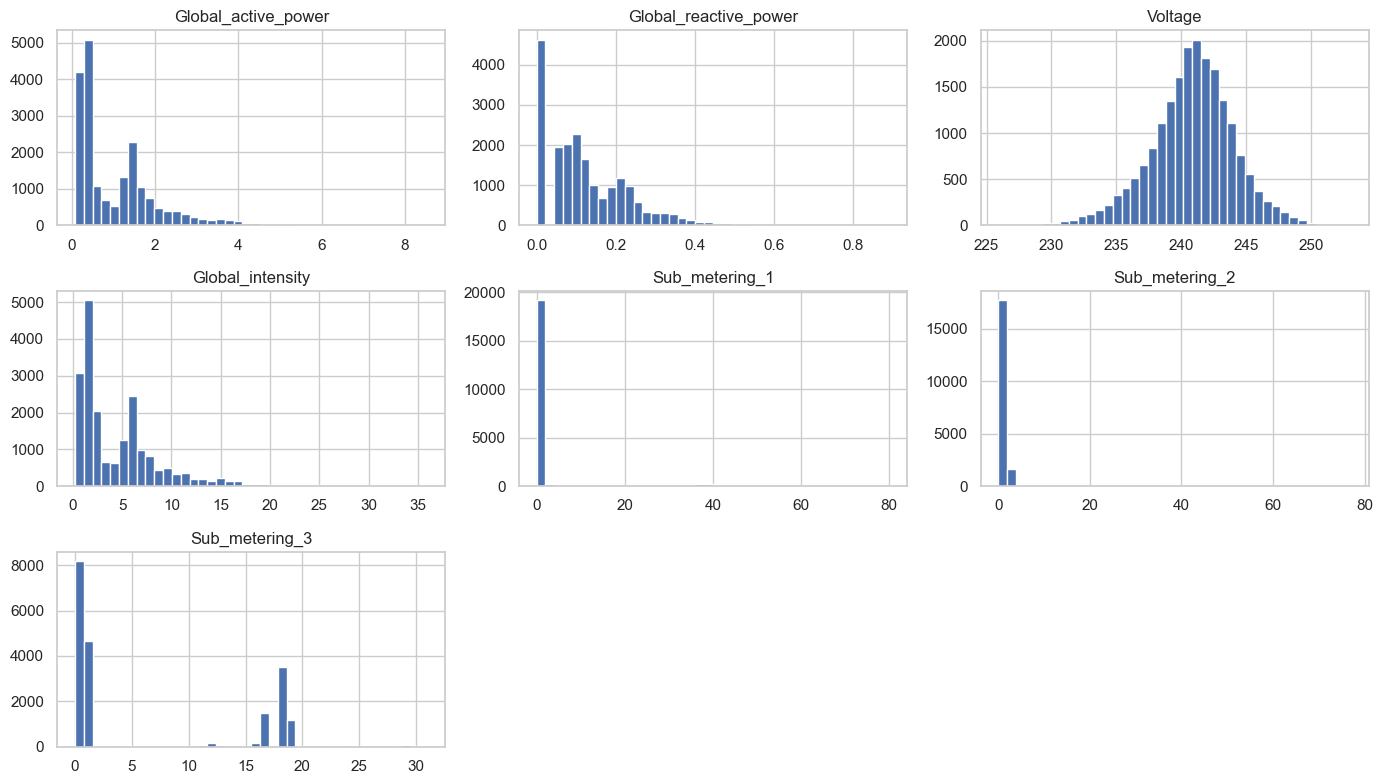

In [9]:
pastikan('data')
num_cols = ['Global_active_power','Global_reactive_power','Voltage','Global_intensity',
            'Sub_metering_1','Sub_metering_2','Sub_metering_3']
data[num_cols].hist(bins=40, figsize=(14,8)); plt.tight_layout(); plt.show()

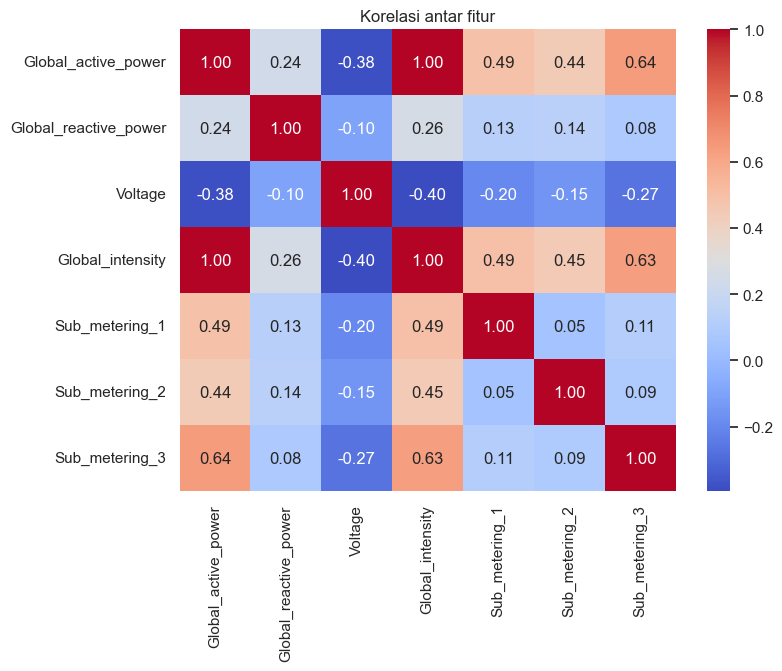

In [10]:
pastikan('data')
plt.figure(figsize=(8,6))
sns.heatmap(data[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Korelasi antar fitur'); plt.show()

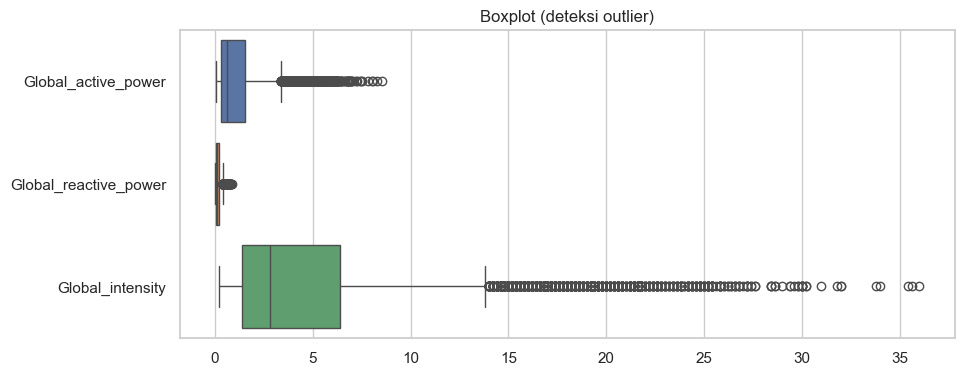

In [11]:
pastikan('data')
plt.figure(figsize=(10,4))
sns.boxplot(data=data[['Global_active_power','Global_reactive_power','Global_intensity']], orient='h')
plt.title('Boxplot (deteksi outlier)'); plt.show()

## 3b. EXDA (Explanatory Data Analysis) – menjelaskan pola dan insight

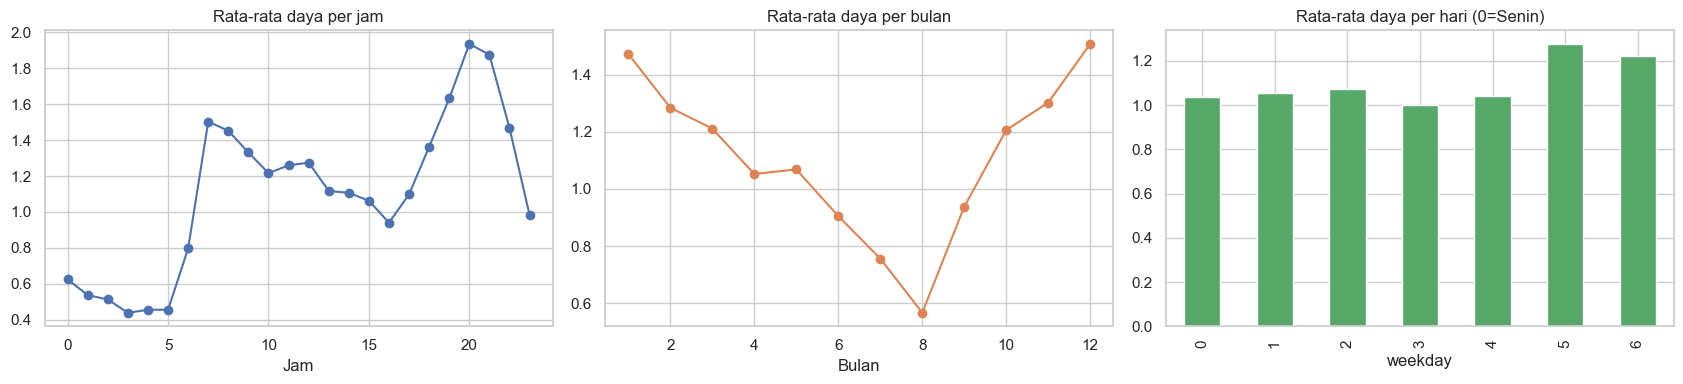

In [12]:
pastikan('data')
fig, ax = plt.subplots(1, 3, figsize=(17,4))
data.groupby('hour')['Global_active_power'].mean().plot(ax=ax[0], marker='o')
ax[0].set_title('Rata-rata daya per jam'); ax[0].set_xlabel('Jam')
data.groupby('month')['Global_active_power'].mean().plot(ax=ax[1], marker='o', color='C1')
ax[1].set_title('Rata-rata daya per bulan'); ax[1].set_xlabel('Bulan')
data.groupby('weekday')['Global_active_power'].mean().plot(kind='bar', ax=ax[2], color='C2')
ax[2].set_title('Rata-rata daya per hari (0=Senin)')
plt.tight_layout(); plt.show()

**Insight (penjelasan):**
- Konsumsi listrik memuncak pada **pagi dan malam hari** (aktivitas rumah) dan paling rendah dini hari.
- Konsumsi lebih tinggi pada **bulan-bulan musim dingin** (pemanas), lebih rendah pada musim panas (Juli–Agustus, kemungkinan penghuni berlibur).
- `Global_active_power` dan `Global_intensity` berkorelasi ~1 (redundan), sedangkan `Voltage` berkorelasi negatif: saat beban naik, tegangan sedikit turun.

# 4. Data Splitting
Data dibagi menjadi **data latih (train)** untuk membangun model dan **data uji (test)** untuk menilai performa pada data baru. Tujuannya mencegah *overfitting* dan memberi estimasi performa yang jujur.

Dua target yang dipakai dalam praktikum:
- **Klasifikasi:** `high_usage` = 1 jika `Global_active_power` di atas persentil 75, selain itu 0.
- **Regresi:** memprediksi nilai `Global_active_power`.

Fitur klasifikasi tidak memuat `Global_active_power`/`Global_intensity` agar tidak terjadi *data leakage*.

# 5. Konversi ke Pandas DataFrame
Array NumPy (hasil scaling/PCA/split) sering perlu dikembalikan ke DataFrame agar kolomnya berlabel.

In [13]:
thr = data['Global_active_power'].quantile(0.75)
data['high_usage'] = (data['Global_active_power'] > thr).astype(int)

feat_cls = ['Global_reactive_power','Voltage','Sub_metering_1','Sub_metering_2',
            'Sub_metering_3','hour','month','weekday']
X = data[feat_cls]
y = data['high_usage']

# contoh konversi array NumPy -> DataFrame
arr = StandardScaler().fit_transform(X)
X_df = pd.DataFrame(arr, columns=feat_cls, index=X.index)
print(type(arr), '->', type(X_df))
X_df.head()

<class 'numpy.ndarray'> -> <class 'pandas.core.frame.DataFrame'>


,Global_reactive_power,Voltage,Sub_metering_1,Sub_metering_2,Sub_metering_3,hour,month,weekday
datetime,,,,,,,,
2006-12-16 18:22:00,-1.112909,-1.649128,-0.185701,-0.055680,1.231061,0.941723,1.629806,1.005510
2006-12-16 20:41:00,-0.456303,-1.982946,-0.185701,-0.222937,1.231061,1.230509,1.629806,1.005510
2006-12-17 01:03:00,0.732686,-0.530220,-0.185701,-0.222937,-0.772907,-1.512956,1.629806,1.506861
2006-12-17 02:39:00,-1.112909,1.404687,-0.185701,-0.222937,-0.772907,-1.368563,1.629806,1.506861
2006-12-17 03:07:00,0.164811,1.936323,-0.185701,0.278834,-0.772907,-1.224170,1.629806,1.506861


# 6. Sklearn Train Test Split

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RS, stratify=y)
print('Train:', X_train.shape, ' Test:', X_test.shape)
print('Proporsi kelas train:', y_train.mean().round(3), ' test:', y_test.mean().round(3))

Train: (16000, 8)  Test: (4000, 8)
Proporsi kelas train: 0.25  test: 0.25


`stratify=y` menjaga proporsi kelas tetap sama di train dan test.

# 7. Sklearn Cross Validation Split

In [15]:
kf  = KFold(n_splits=5, shuffle=True, random_state=RS)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)
for i, (tr, te) in enumerate(skf.split(X, y), 1):
    print(f'Fold {i}: train={len(tr)}, test={len(te)}, proporsi kelas 1 di test={y.iloc[te].mean():.3f}')

Fold 1: train=16000, test=4000, proporsi kelas 1 di test=0.250
Fold 2: train=16000, test=4000, proporsi kelas 1 di test=0.250
Fold 3: train=16000, test=4000, proporsi kelas 1 di test=0.250
Fold 4: train=16000, test=4000, proporsi kelas 1 di test=0.250
Fold 5: train=16000, test=4000, proporsi kelas 1 di test=0.250


In [16]:
pastikan('data','X_train','X_test','y_train','y_test','skf','feat_cls','feat_reg')
scores = cross_val_score(DecisionTreeClassifier(max_depth=5, random_state=RS), X, y, cv=skf)
print('Akurasi tiap fold:', scores.round(3))
print(f'Rata-rata: {scores.mean():.3f} (+/- {scores.std():.3f})')

[auto] data, target, dan split dibuat.
Akurasi tiap fold: [0.87  0.861 0.871 0.871 0.879]
Rata-rata: 0.870 (+/- 0.006)


# 8. Supervised Learning
Pembelajaran **terawasi**: model belajar dari data berlabel (fitur X dan target y). Dua jenis utama:
- **Klasifikasi** → target kategori (contoh: konsumsi tinggi/rendah)
- **Regresi** → target numerik (contoh: besar daya aktif)

# 9. Klasifikasi
Memprediksi kelas `high_usage` (0 = normal, 1 = tinggi) dari fitur waktu, voltase, daya reaktif, dan sub-metering.

# 10. Sklearn Decision Tree

In [17]:
pastikan('data','X_train','X_test','y_train','y_test','skf','feat_cls','feat_reg')
dt = DecisionTreeClassifier(max_depth=4, random_state=RS)
dt.fit(X_train, y_train)
pred_dt = dt.predict(X_test)
print('Akurasi:', round(accuracy_score(y_test, pred_dt), 4))
print(classification_report(y_test, pred_dt))

Akurasi: 0.866
              precision    recall  f1-score   support

           0       0.88      0.95      0.91      3000
           1       0.80      0.62      0.70      1000

    accuracy                           0.87      4000
   macro avg       0.84      0.79      0.81      4000
weighted avg       0.86      0.87      0.86      4000



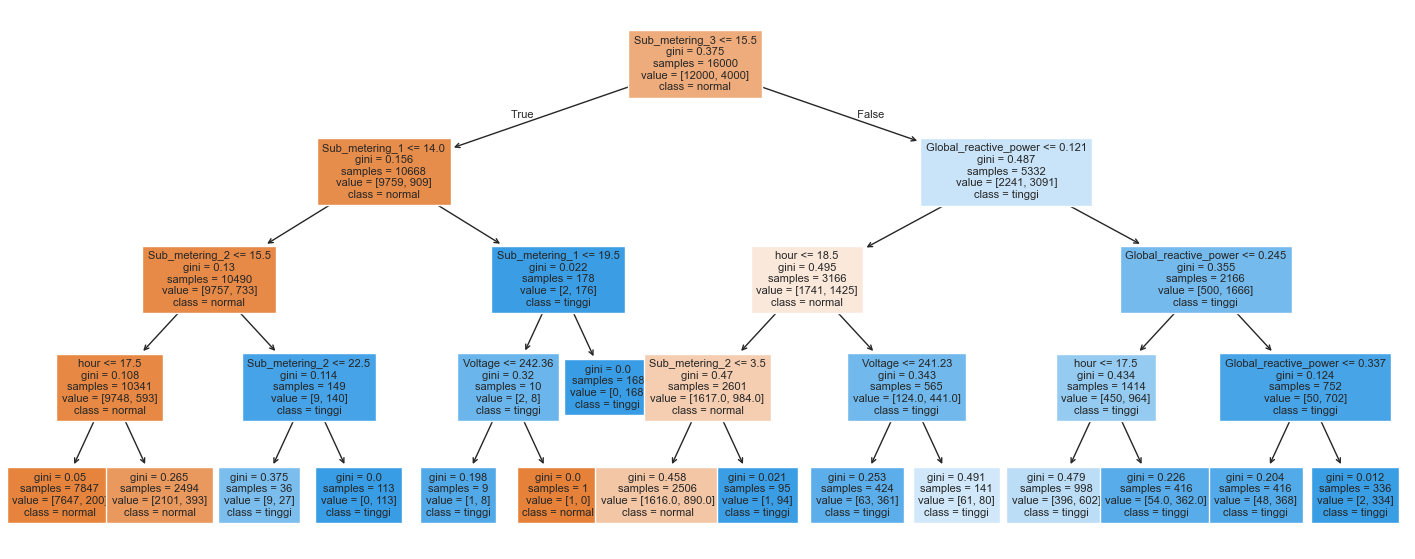

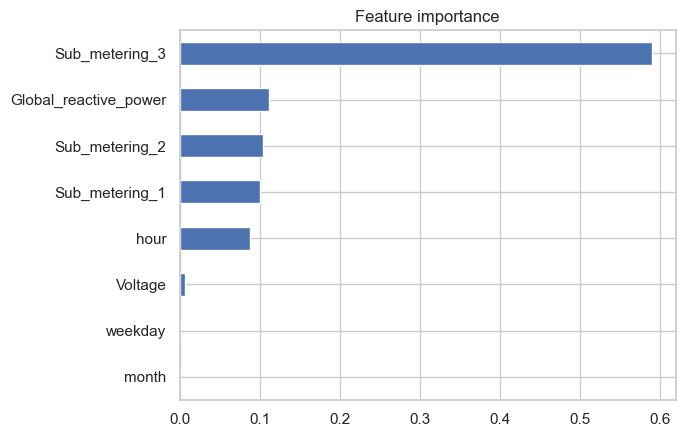

In [18]:
plt.figure(figsize=(18,7))
plot_tree(dt, feature_names=feat_cls, class_names=['normal','tinggi'], filled=True, fontsize=8)
plt.show()
pd.Series(dt.feature_importances_, index=feat_cls).sort_values().plot(kind='barh', title='Feature importance')
plt.show()

# 11. Sklearn Linear Regression
Memprediksi `Global_active_power` (nilai kontinu).

In [19]:
pastikan('data')
feat_reg = ['Global_reactive_power','Voltage','Sub_metering_1','Sub_metering_2','Sub_metering_3','hour']
Xr, yr = data[feat_reg], data['Global_active_power']
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(Xr, yr, test_size=0.2, random_state=RS)

lr = LinearRegression().fit(Xr_tr, yr_tr)
pred_lr = lr.predict(Xr_te)
print('R2  :', round(r2_score(yr_te, pred_lr), 4))
print('RMSE:', round(float(np.sqrt(mean_squared_error(yr_te, pred_lr))), 4))
print(pd.Series(lr.coef_, index=feat_reg).round(4))

R2  : 0.7703
RMSE: 0.5043
Global_reactive_power    0.7377
Voltage                 -0.0290
Sub_metering_1           0.0628
Sub_metering_2           0.0607
Sub_metering_3           0.0657
hour                     0.0198
dtype: float64


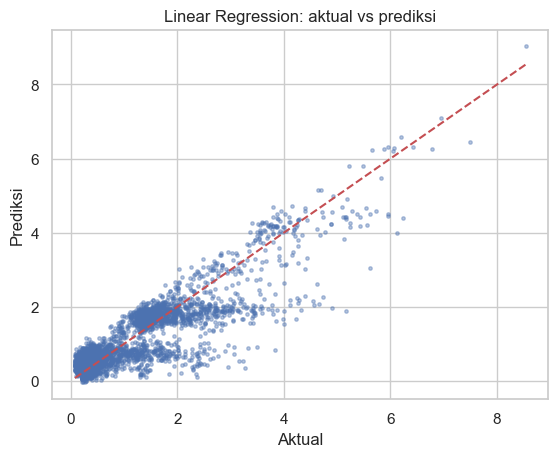

In [20]:
plt.scatter(yr_te, pred_lr, s=6, alpha=.4)
plt.plot([yr_te.min(), yr_te.max()], [yr_te.min(), yr_te.max()], 'r--')
plt.xlabel('Aktual'); plt.ylabel('Prediksi'); plt.title('Linear Regression: aktual vs prediksi'); plt.show()

# 12. Sklearn Logistic Regression

Akurasi: 0.8598
              precision    recall  f1-score   support

           0       0.88      0.93      0.91      3000
           1       0.76      0.64      0.69      1000

    accuracy                           0.86      4000
   macro avg       0.82      0.78      0.80      4000
weighted avg       0.85      0.86      0.86      4000



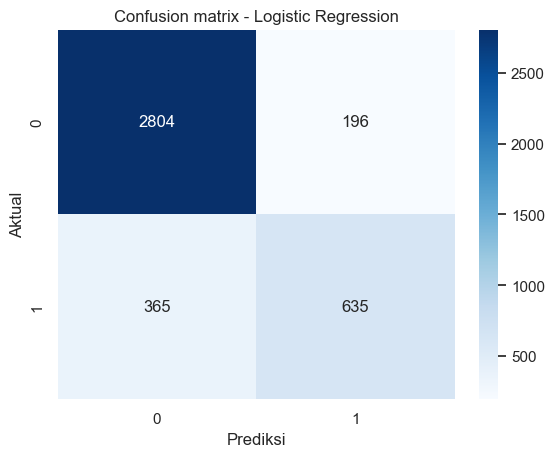

In [21]:
pastikan('data','X_train','X_test','y_train','y_test','skf','feat_cls','feat_reg')
sc = StandardScaler().fit(X_train)
logreg = LogisticRegression(max_iter=1000, random_state=RS)
logreg.fit(sc.transform(X_train), y_train)
pred_lg = logreg.predict(sc.transform(X_test))
print('Akurasi:', round(accuracy_score(y_test, pred_lg), 4))
print(classification_report(y_test, pred_lg))
sns.heatmap(confusion_matrix(y_test, pred_lg), annot=True, fmt='d', cmap='Blues')
plt.title('Confusion matrix - Logistic Regression'); plt.xlabel('Prediksi'); plt.ylabel('Aktual'); plt.show()

# 13. Unsupervised Learning
Pembelajaran **tak terawasi**: tidak ada label. Model mencari struktur tersembunyi pada data, misalnya pengelompokan (clustering) dan reduksi dimensi.

# 14. Sklearn K-Means

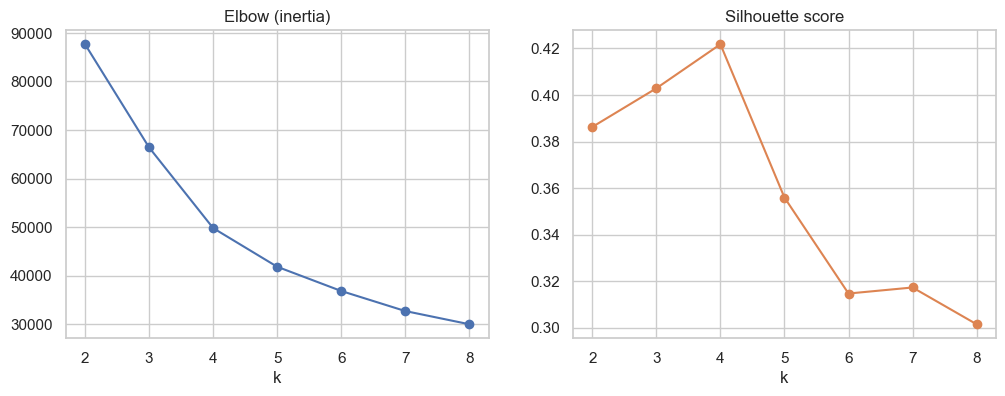

In [22]:
pastikan('data')
feat_un = ['Global_active_power','Global_reactive_power','Voltage',
           'Sub_metering_1','Sub_metering_2','Sub_metering_3']
Xu = StandardScaler().fit_transform(data[feat_un])

ks = range(2, 9)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RS).fit(Xu)
    inertia.append(km.inertia_); sil.append(silhouette_score(Xu, km.labels_))
fig, ax = plt.subplots(1, 2, figsize=(12,4))
ax[0].plot(ks, inertia, 'o-'); ax[0].set_title('Elbow (inertia)'); ax[0].set_xlabel('k')
ax[1].plot(ks, sil, 'o-', color='C1'); ax[1].set_title('Silhouette score'); ax[1].set_xlabel('k')
plt.show()

In [23]:
best_k = list(ks)[int(np.argmax(sil))]
print('k terbaik menurut silhouette:', best_k)
km = KMeans(n_clusters=best_k, n_init=10, random_state=RS).fit(Xu)
data['cluster'] = km.labels_
print(data['cluster'].value_counts().sort_index())
data.groupby('cluster')[feat_un].mean().round(2)

k terbaik menurut silhouette: 4
cluster
0    12471
1     6480
2      559
3      490
Name: count, dtype: int64


,Global_active_power,Global_reactive_power,Voltage,Sub_metering_1,Sub_metering_2,Sub_metering_3
cluster,,,,,,
0,0.50,0.11,241.68,0.05,0.43,0.44
1,1.81,0.13,239.76,0.20,0.45,17.51
2,3.94,0.20,237.22,36.57,1.48,11.69
3,3.81,0.20,237.99,1.69,35.71,11.62


# 15. Sklearn PCA

Explained variance ratio: [0.385 0.166 0.157 0.139 0.128 0.025]


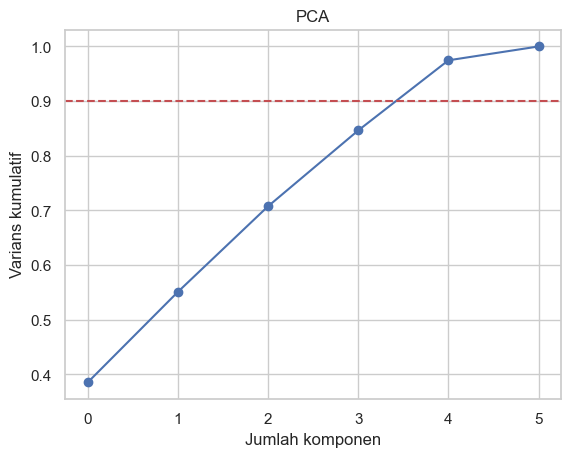

In [24]:
pastikan('Xu','feat_un','cluster')
pca = PCA().fit(Xu)
print('Explained variance ratio:', pca.explained_variance_ratio_.round(3))
plt.plot(np.cumsum(pca.explained_variance_ratio_), 'o-'); plt.axhline(.9, ls='--', c='r')
plt.xlabel('Jumlah komponen'); plt.ylabel('Varians kumulatif'); plt.title('PCA'); plt.show()

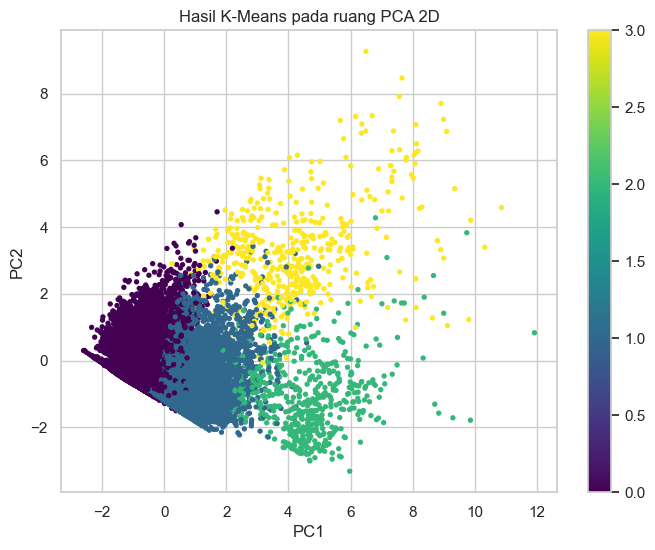

,Global_active_power,Global_reactive_power,Voltage,Sub_metering_1,Sub_metering_2,Sub_metering_3
PC1,0.61,0.24,-0.38,0.36,0.32,0.45
PC2,-0.04,0.66,0.22,-0.16,0.58,-0.39


In [25]:
pastikan('Xu','feat_un','cluster')
pca2 = PCA(n_components=2)
Xp = pca2.fit_transform(Xu)
Xp_df = pd.DataFrame(Xp, columns=['PC1','PC2'], index=data.index)   # konversi ke DataFrame
plt.figure(figsize=(8,6))
plt.scatter(Xp_df.PC1, Xp_df.PC2, c=data['cluster'], cmap='viridis', s=8)
plt.xlabel('PC1'); plt.ylabel('PC2'); plt.title('Hasil K-Means pada ruang PCA 2D'); plt.colorbar(); plt.show()
pd.DataFrame(pca2.components_, columns=feat_un, index=['PC1','PC2']).round(2)

# 16. Support Vector Machine (SVM)
SVM mencari **hyperplane** yang memisahkan kelas dengan **margin** terbesar. Titik terdekat ke hyperplane disebut *support vector*. Dengan **kernel** (linear, RBF, polynomial) SVM dapat menangani batas keputusan non-linear. Parameter penting:
- `C`: toleransi kesalahan (besar → margin sempit, risiko overfit)
- `gamma`: jangkauan pengaruh satu titik pada kernel RBF
- Wajib dilakukan **scaling** fitur.

# 17. Sklearn SVM untuk Klasifikasi

In [26]:
pastikan('data','X_train','X_test','y_train','y_test','skf','feat_cls','feat_reg')
svc = Pipeline([('sc', StandardScaler()), ('svm', SVC(kernel='rbf', C=1, gamma='scale', random_state=RS))])
svc.fit(X_train, y_train)
pred_svc = svc.predict(X_test)
print('Akurasi:', round(accuracy_score(y_test, pred_svc), 4))
print(classification_report(y_test, pred_svc))

Akurasi: 0.8845
              precision    recall  f1-score   support

           0       0.90      0.96      0.93      3000
           1       0.84      0.67      0.74      1000

    accuracy                           0.88      4000
   macro avg       0.87      0.81      0.83      4000
weighted avg       0.88      0.88      0.88      4000



# 18. Sklearn SVR (Support Vector Regression)
SVR lambat pada data besar, sehingga dipakai subset 5.000 baris.

In [27]:
pastikan('data','X_train','X_test','y_train','y_test','skf','feat_cls','feat_reg')
sub = data.sample(5000, random_state=RS)
Xs_tr, Xs_te, ys_tr, ys_te = train_test_split(sub[feat_reg], sub['Global_active_power'],
                                              test_size=0.2, random_state=RS)
svr = Pipeline([('sc', StandardScaler()), ('svr', SVR(kernel='rbf', C=10, epsilon=0.1))])
svr.fit(Xs_tr, ys_tr)
pred_svr = svr.predict(Xs_te)
print('R2  :', round(r2_score(ys_te, pred_svr), 4))
print('RMSE:', round(float(np.sqrt(mean_squared_error(ys_te, pred_svr))), 4))

R2  : 0.754
RMSE: 0.5074


# 19. Sklearn dengan Teknik Grid Search
Mencari kombinasi hyperparameter terbaik secara sistematis dengan cross-validation.

In [28]:
pastikan('data','X_train','X_test','y_train','y_test','skf','feat_cls','feat_reg')
pipe = Pipeline([('sc', StandardScaler()), ('svm', SVC(random_state=RS))])
param_grid = {'svm__C': [0.1, 1, 10],
              'svm__gamma': ['scale', 0.01, 0.1],
              'svm__kernel': ['rbf', 'linear']}
gs = GridSearchCV(pipe, param_grid, cv=3, scoring='accuracy', n_jobs=-1)
gs.fit(X_train.iloc[:5000], y_train.iloc[:5000])
print('Parameter terbaik:', gs.best_params_)
print('Akurasi CV terbaik:', round(gs.best_score_, 4))
print('Akurasi pada data uji:', round(accuracy_score(y_test, gs.predict(X_test)), 4))
pd.DataFrame(gs.cv_results_)[['params','mean_test_score','rank_test_score']].sort_values('rank_test_score').head()

Parameter terbaik: {'svm__C': 10, 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}
Akurasi CV terbaik: 0.885
Akurasi pada data uji: 0.8818


,params,mean_test_score,rank_test_score
12,"{'svm__C': 10, 'svm__gamma': 'scale', 'svm__ke...",0.885001,1
16,"{'svm__C': 10, 'svm__gamma': 0.1, 'svm__kernel...",0.884200,2
6,"{'svm__C': 1, 'svm__gamma': 'scale', 'svm__ker...",0.884200,3
10,"{'svm__C': 1, 'svm__gamma': 0.1, 'svm__kernel'...",0.882600,4
14,"{'svm__C': 10, 'svm__gamma': 0.01, 'svm__kerne...",0.881000,5


In [29]:
pastikan('data','X_train','X_test','y_train','y_test','skf','feat_cls','feat_reg')
gs_dt = GridSearchCV(DecisionTreeClassifier(random_state=RS),
                     {'max_depth': [2,3,4,5,7,10], 'min_samples_leaf': [1,5,20]}, cv=5)
gs_dt.fit(X_train, y_train)
print('Decision Tree terbaik:', gs_dt.best_params_, round(gs_dt.best_score_, 4))

Decision Tree terbaik: {'max_depth': 10, 'min_samples_leaf': 20} 0.8873


# 20. Model Klasifikasi Gambar
Dataset gambar: **Digits** bawaan scikit-learn (1.797 gambar angka 0–9 ukuran 8×8 piksel). Setiap gambar diratakan menjadi 64 fitur, lalu diklasifikasi dengan SVM.

Bentuk data: (1797, 64) | jumlah kelas: 10


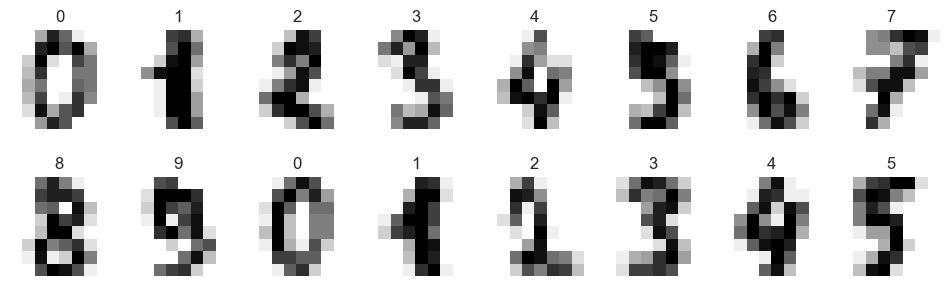

In [30]:
from sklearn.datasets import load_digits
digits = load_digits()
Xi, yi = digits.data, digits.target
print('Bentuk data:', Xi.shape, '| jumlah kelas:', len(np.unique(yi)))

fig, axes = plt.subplots(2, 8, figsize=(12,3.5))
for ax, img, lab in zip(axes.ravel(), digits.images, digits.target):
    ax.imshow(img, cmap='gray_r'); ax.set_title(lab); ax.axis('off')
plt.show()

In [31]:
Xi_tr, Xi_te, yi_tr, yi_te = train_test_split(Xi, yi, test_size=0.25, random_state=RS, stratify=yi)
gs_img = GridSearchCV(Pipeline([('sc', StandardScaler()), ('svm', SVC())]),
                      {'svm__C': [1, 10], 'svm__gamma': [0.001, 0.01]}, cv=3)
gs_img.fit(Xi_tr, yi_tr)
pred_img = gs_img.predict(Xi_te)
print('Parameter terbaik:', gs_img.best_params_)
print('Akurasi test:', round(accuracy_score(yi_te, pred_img), 4))
print(classification_report(yi_te, pred_img))

Parameter terbaik: {'svm__C': 10, 'svm__gamma': 0.01}
Akurasi test: 0.9822
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        45
           1       0.96      0.98      0.97        46
           2       1.00      1.00      1.00        44
           3       1.00      1.00      1.00        46
           4       0.96      0.98      0.97        45
           5       1.00      0.98      0.99        46
           6       0.98      1.00      0.99        45
           7       0.96      1.00      0.98        45
           8       1.00      0.93      0.96        43
           9       0.98      0.96      0.97        45

    accuracy                           0.98       450
   macro avg       0.98      0.98      0.98       450
weighted avg       0.98      0.98      0.98       450



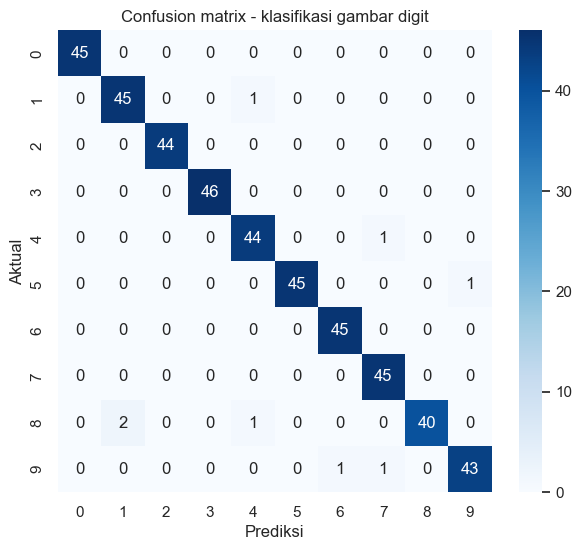

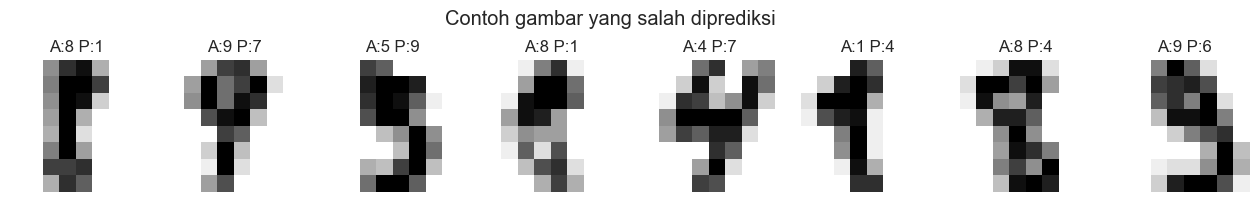

In [32]:
plt.figure(figsize=(7,6))
sns.heatmap(confusion_matrix(yi_te, pred_img), annot=True, fmt='d', cmap='Blues')
plt.title('Confusion matrix - klasifikasi gambar digit'); plt.xlabel('Prediksi'); plt.ylabel('Aktual'); plt.show()

idx = np.where(pred_img != yi_te)[0][:8]
if len(idx):
    fig, axes = plt.subplots(1, len(idx), figsize=(2*len(idx), 2.4))
    for ax, i in zip(np.atleast_1d(axes), idx):
        ax.imshow(Xi_te[i].reshape(8,8), cmap='gray_r'); ax.axis('off')
        ax.set_title(f'A:{yi_te[i]} P:{pred_img[i]}')
    plt.suptitle('Contoh gambar yang salah diprediksi'); plt.show()

# Kesimpulan
- Pipeline lengkap: load → clean → EDA/EXDA → split → model supervised (klasifikasi & regresi) → unsupervised (K-Means, PCA) → SVM/SVR → Grid Search → klasifikasi gambar.
- Hasil modeling dapat dibandingkan dari metrik di tiap bagian (akurasi, R², RMSE, silhouette).
- Scaling wajib untuk SVM, Logistic Regression, K-Means, dan PCA.